## Model Training


#### 1.1 Import Data and Required Packages
##### Importing Pandas, Numpy, Matplotlib, Seaborn and Warnings Library.


In [2]:
# Basic Import
import os
import numpy as np
import pandas as pd
import matplotlib
try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except Exception:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt 
import seaborn as sns

# Modelling
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

import warnings
warnings.filterwarnings('ignore')


#### Import the CSV Data as Pandas DataFrame


In [3]:
# Locate data directory (works from project root or notebook directory)
data_dir = 'notebook/Data' if os.path.exists('notebook/Data') else 'data'

train_df = pd.read_csv(f'{data_dir}/train.csv')
stores_df = pd.read_csv(f'{data_dir}/stores.csv').rename(columns={'type': 'store_type'})
oil_df = pd.read_csv(f'{data_dir}/oil.csv')
holidays_df = pd.read_csv(f'{data_dir}/holidays_events.csv')
transactions_df = pd.read_csv(f'{data_dir}/transactions.csv')

# Handle missing oil prices (ffill & bfill)
oil_df['dcoilwtico'] = oil_df['dcoilwtico'].ffill().bfill()

# Filter transferred holidays and deduplicate by date to avoid multiplying rows
holidays_clean = holidays_df[holidays_df['transferred'] == False].drop_duplicates(subset=['date']).rename(columns={'type': 'holiday_type'})

# Merge all datasets into df
df = train_df.merge(stores_df, on='store_nbr', how='left') \
             .merge(oil_df, on='date', how='left') \
             .merge(holidays_clean[['date', 'holiday_type']], on='date', how='left') \
             .merge(transactions_df, on=['date', 'store_nbr'], how='left')

# Fill missing values
df['holiday_type'] = df['holiday_type'].fillna('None')
df['transactions'] = df['transactions'].fillna(0)
df['dcoilwtico'] = df['dcoilwtico'].ffill().bfill()

# Feature Engineering: Extract date features
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['dayofweek'] = df['date'].dt.dayofweek
df['is_weekend'] = (df['dayofweek'] >= 5).astype(int)

# Filter for 2017 data (reflects recent patterns and trains quickly)
df_model = df[df['year'] == 2017].copy()


#### Show Top 5 Records


In [4]:
df_model.head()


,id,date,store_nbr,family,sales,onpromotion,city,state,store_type,cluster,dcoilwtico,holiday_type,transactions,year,month,day,dayofweek,is_weekend
2596374,2596374,2017-01-01,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13,53.75,None,0.0,2017,1,1,6,1
2596375,2596375,2017-01-01,1,BABY CARE,0.0,0,Quito,Pichincha,D,13,53.75,None,0.0,2017,1,1,6,1
2596376,2596376,2017-01-01,1,BEAUTY,0.0,0,Quito,Pichincha,D,13,53.75,None,0.0,2017,1,1,6,1
2596377,2596377,2017-01-01,1,BEVERAGES,0.0,0,Quito,Pichincha,D,13,53.75,None,0.0,2017,1,1,6,1
2596378,2596378,2017-01-01,1,BOOKS,0.0,0,Quito,Pichincha,D,13,53.75,None,0.0,2017,1,1,6,1


#### Preparing X and Y variables


In [5]:
# Drop identifier and target columns to prevent leakage
X = df_model.drop(columns=['id', 'date', 'year', 'sales'])


In [6]:
X.head()


,store_nbr,family,onpromotion,city,state,store_type,cluster,dcoilwtico,holiday_type,transactions,month,day,dayofweek,is_weekend
2596374,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,53.75,None,0.0,1,1,6,1
2596375,1,BABY CARE,0,Quito,Pichincha,D,13,53.75,None,0.0,1,1,6,1
2596376,1,BEAUTY,0,Quito,Pichincha,D,13,53.75,None,0.0,1,1,6,1
2596377,1,BEVERAGES,0,Quito,Pichincha,D,13,53.75,None,0.0,1,1,6,1
2596378,1,BOOKS,0,Quito,Pichincha,D,13,53.75,None,0.0,1,1,6,1


In [7]:
print("Categories in 'family' variable:        ", df_model['family'].nunique(), "unique families")
print("Categories in 'store_type' variable:    ", df_model['store_type'].unique())
print("Categories in 'holiday_type' variable:  ", df_model['holiday_type'].unique())
print("Categories in 'city' variable:          ", df_model['city'].nunique(), "cities")
print("Categories in 'state' variable:         ", df_model['state'].nunique(), "states")


Categories in 'family' variable:         33 unique families
Categories in 'store_type' variable:     ['D' 'C' 'B' 'E' 'A']
Categories in 'holiday_type' variable:   ['None' 'Transfer' 'Holiday' 'Additional' 'Event']
Categories in 'city' variable:           22 cities
Categories in 'state' variable:          16 states


In [8]:
y = df_model['sales']


In [9]:
y


2596374       0.000
2596375       0.000
2596376       0.000
2596377       0.000
2596378       0.000
             ...   
3000883     438.133
3000884     154.553
3000885    2419.729
3000886     121.000
3000887      16.000
Name: sales, Length: 404514, dtype: float64

In [10]:
# Create Column Transformer with OrdinalEncoder for categoricals and StandardScaler for numerical features
num_features = X.select_dtypes(exclude=['object', 'string']).columns
cat_features = X.select_dtypes(include=['object', 'string']).columns

from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

numeric_transformer = StandardScaler()
cat_transformer = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

preprocessor = ColumnTransformer(
    [
        ("OrdinalEncoder", cat_transformer, cat_features),
        ("StandardScaler", numeric_transformer, num_features),        
    ]
)


In [11]:
X = preprocessor.fit_transform(X)


In [12]:
X.shape


(404514, 14)

In [13]:
# Separate dataset into train and test chronologically to prevent future leakage in time-series
train_mask = (df_model['date'] < '2017-08-01').values
test_mask = (df_model['date'] >= '2017-08-01').values

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y.iloc[train_mask], y.iloc[test_mask]

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")


X_train shape: (377784, 14), X_test shape: (26730, 14)


#### Create an Evaluate Function to give all metrics after model Training


In [14]:
def evaluate_model(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mean_squared_error(true, predicted))
    r2_square = r2_score(true, predicted)
    return mae, rmse, r2_square


In [15]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Decision Tree": DecisionTreeRegressor(max_depth=12, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=40, max_depth=12, random_state=42, n_jobs=-1),
    "XGBRegressor": XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1), 
    "LightGBM Regressor": LGBMRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, verbose=-1, n_jobs=-1),
    "CatBoosting Regressor": CatBoostRegressor(iterations=100, depth=6, verbose=False, random_state=42)
}

model_list = []
r2_list = []

for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train) # Train model

    # Make predictions (sales cannot be negative)
    y_train_pred = np.clip(model.predict(X_train), 0, None)
    y_test_pred = np.clip(model.predict(X_test), 0, None)
    
    # Evaluate Train and Test dataset
    model_train_mae, model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)
    model_test_mae, model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)

    print(list(models.keys())[i])
    model_list.append(list(models.keys())[i])
    
    print('Model performance for Training set')
    print("- Root Mean Squared Error: {:.4f}".format(model_train_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_train_mae))
    print("- R2 Score: {:.4f}".format(model_train_r2))

    print('----------------------------------')
    
    print('Model performance for Test set')
    print("- Root Mean Squared Error: {:.4f}".format(model_test_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_test_mae))
    print("- R2 Score: {:.4f}".format(model_test_r2))
    r2_list.append(model_test_r2)
    
    print('='*35)
    print('\n')


Linear Regression
Model performance for Training set
- Root Mean Squared Error: 1066.7350
- Mean Absolute Error: 438.8005
- R2 Score: 0.3872
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 1001.4730
- Mean Absolute Error: 423.9247
- R2 Score: 0.3522


Ridge
Model performance for Training set
- Root Mean Squared Error: 1066.7350
- Mean Absolute Error: 438.8006
- R2 Score: 0.3872
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 1001.4730
- Mean Absolute Error: 423.9249
- R2 Score: 0.3522


Decision Tree
Model performance for Training set
- Root Mean Squared Error: 218.1717
- Mean Absolute Error: 72.6735
- R2 Score: 0.9744
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 326.7364
- Mean Absolute Error: 96.8926
- R2 Score: 0.9310


Random Forest Regressor
Model performance for Training set
- Root Mean Squared Error: 189.1085
- Mean Absolute Error: 65.9699
- R

### Results


In [16]:
pd.DataFrame(list(zip(model_list, r2_list)), columns=['Model Name', 'R2_Score']).sort_values(by=["R2_Score"], ascending=False)


,Model Name,R2_Score
6,CatBoosting Regressor,0.950783
4,XGBRegressor,0.949908
3,Random Forest Regressor,0.949596
5,LightGBM Regressor,0.944883
2,Decision Tree,0.931047
1,Ridge,0.352202
0,Linear Regression,0.352202


## Best Model (XGBRegressor)


In [17]:
best_model = XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
best_model = best_model.fit(X_train, y_train)
y_pred = np.clip(best_model.predict(X_test), 0, None)
score = r2_score(y_test, y_pred) * 100
print("Accuracy (R2 Score) of the model is %.2f%%" % score)


Accuracy (R2 Score) of the model is 94.99%


## Plot y_pred and y_test


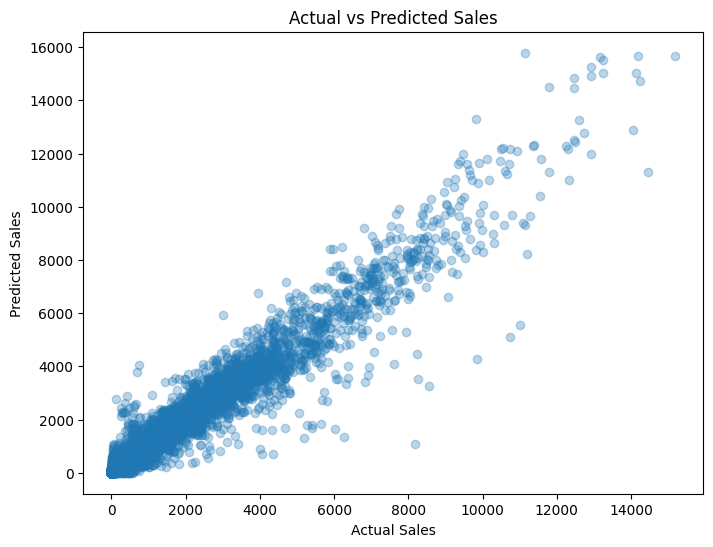

In [18]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales')
plt.show()


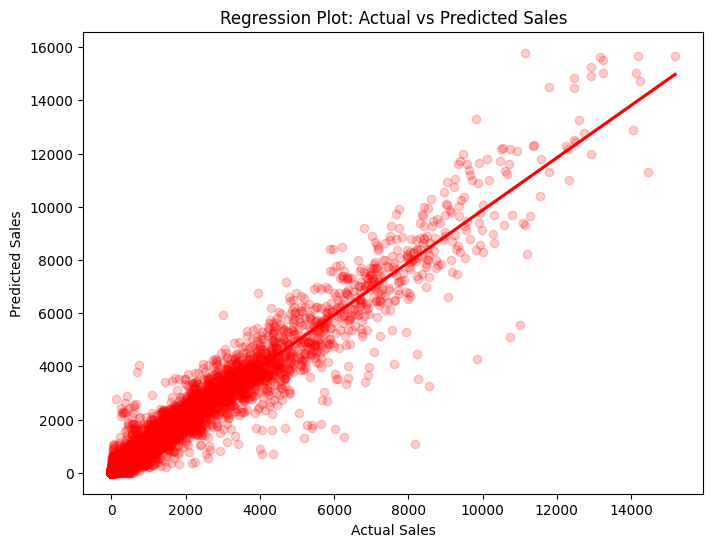

In [19]:
plt.figure(figsize=(8, 6))
sns.regplot(x=y_test, y=y_pred, ci=None, color='red', scatter_kws={'alpha': 0.2})
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Regression Plot: Actual vs Predicted Sales')
plt.show()


#### Difference between Actual and Predicted Values


In [20]:
pred_df = pd.DataFrame({'Actual Value': y_test.values, 'Predicted Value': np.round(y_pred, 2), 'Difference': np.round(y_test.values - y_pred, 2)})
pred_df.head(20)


,Actual Value,Predicted Value,Difference
0,5.00000,5.680000,-0.68
1,0.00000,5.680000,-5.68
2,4.00000,5.680000,-1.68
3,2627.00000,3187.479980,-560.48
4,0.00000,18.760000,-18.76
5,373.70898,302.190002,71.52
6,11.00000,39.130001,-28.13
7,867.00000,1065.800049,-198.80
8,668.00000,621.150024,46.85
9,133.58800,308.709991,-175.12


In [21]:
# Summary statistics of the prediction difference
pred_df['Difference'].describe()


count    26730.000000
mean       -21.641230
std        277.649508
min      -4635.620000
25%        -42.877500
50%         -8.410000
75%          6.000000
max       7101.550000
Name: Difference, dtype: float64